# Experiment No. 2 — Exploratory Data Analysis (EDA) on a Real-World Business Dataset

- **Name:** Akshit Negi
- **Course & Branch:** B.TECH CSE
- **CUID:** CU24250214
- **SUBJECT:** Mastery in Data Analytics and Visualizations and Career Advancement
- **SEM & Section:** 5th SEM, "B"

**Aim:** Perform EDA — distributions, categorical breakdowns, correlations, outliers, and univariate/bivariate/multivariate analysis — to derive business insights.

**Dataset:** Titanic Survival Dataset, loaded via `seaborn.load_dataset('titanic')` — no download needed.

---

## Steps 1–3: Load dataset and explore its structure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('titanic').dropna(subset=['age', 'embarked'])

print(df.shape)
print(df.info())
print(df.describe())
print(df['class'].value_counts())

(712, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     712 non-null    int64   
 1   pclass       712 non-null    int64   
 2   sex          712 non-null    object  
 3   age          712 non-null    float64 
 4   sibsp        712 non-null    int64   
 5   parch        712 non-null    int64   
 6   fare         712 non-null    float64 
 7   embarked     712 non-null    object  
 8   class        712 non-null    category
 9   who          712 non-null    object  
 10  adult_male   712 non-null    bool    
 11  deck         182 non-null    category
 12  embark_town  712 non-null    object  
 13  alive        712 non-null    object  
 14  alone        712 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 70.0+ KB
None
         survived      pclass         age       sibsp       parch    

## Step 4: Distribution of numerical features (histogram + density plot)

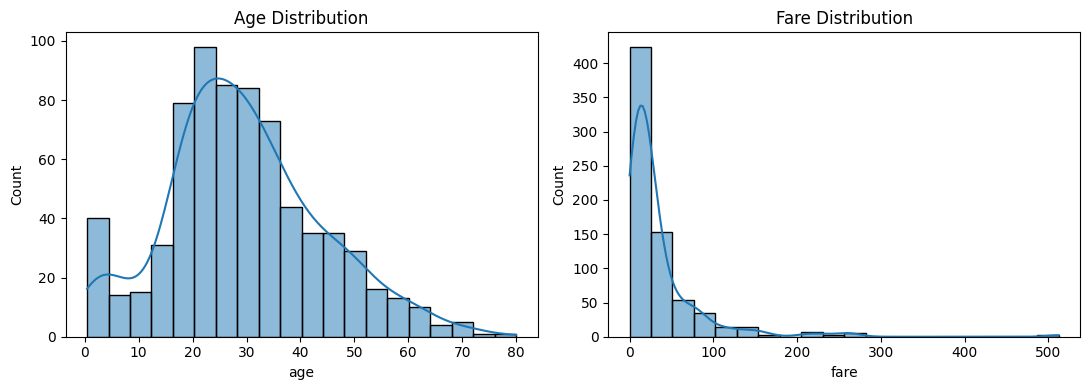

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['age'], kde=True, bins=20, ax=axes[0]).set_title("Age Distribution")
sns.histplot(df['fare'], kde=True, bins=20, ax=axes[1]).set_title("Fare Distribution")
plt.tight_layout(); plt.show()

## Step 5: Categorical variables (bar chart + count plot)

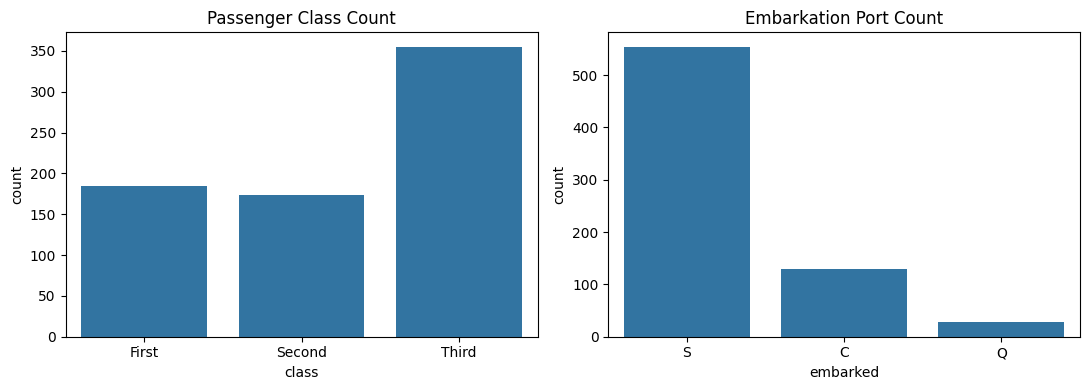

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='class', ax=axes[0]).set_title("Passenger Class Count")
sns.countplot(data=df, x='embarked', ax=axes[1]).set_title("Embarkation Port Count")
plt.tight_layout(); plt.show()

## Step 6: Correlation matrix and heatmap

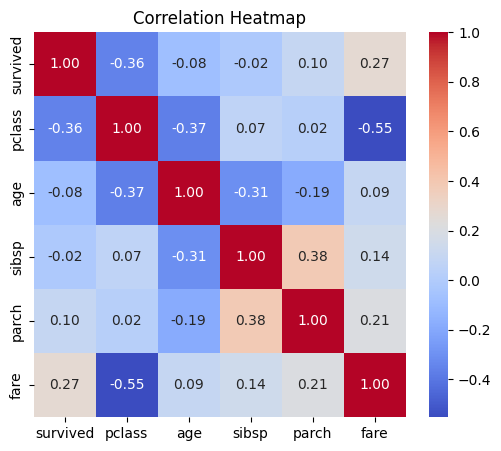

In [4]:
num_df = df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']]
corr = num_df.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Step 7: Outliers and relationships (box plot + scatter plot)

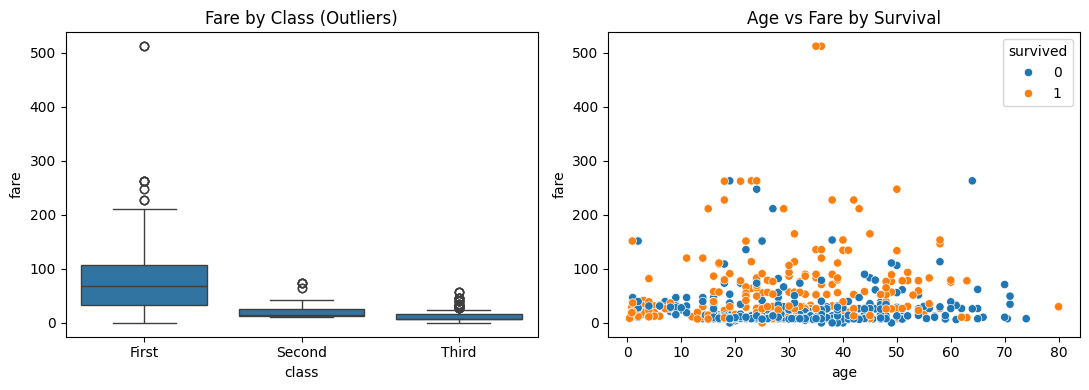

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x='class', y='fare', ax=axes[0]).set_title("Fare by Class (Outliers)")
sns.scatterplot(data=df, x='age', y='fare', hue='survived', ax=axes[1]).set_title("Age vs Fare by Survival")
plt.tight_layout(); plt.show()

## Step 8: Univariate, bivariate, and multivariate analysis

In [6]:
# Univariate: survival rate overall
print("Overall survival rate:", df['survived'].mean().round(2))

# Bivariate: survival rate by sex
print("\nSurvival rate by sex:\n", df.groupby('sex')['survived'].mean().round(2))

# Multivariate: survival rate by class and sex
print("\nSurvival rate by class and sex:\n", df.groupby(['class', 'sex'])['survived'].mean().round(2))

Overall survival rate: 0.4

Survival rate by sex:
 sex
female    0.75
male      0.21
Name: survived, dtype: float64

Survival rate by class and sex:
 class   sex   
First   female    0.96
        male      0.40
Second  female    0.92
        male      0.15
Third   female    0.46
        male      0.15
Name: survived, dtype: float64


/tmp/ipykernel_959/3425108239.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("\nSurvival rate by class and sex:\n", df.groupby(['class', 'sex'])['survived'].mean().round(2))


## Steps 9–10: Key observations and summary

- Fare is right-skewed with high-value outliers, mostly from 1st class passengers.
- `fare` and `pclass` show a strong negative correlation — higher class (lower `pclass` number) pairs with higher fare.
- Survival rate is clearly higher for women and for 1st class passengers, and highest for the combination of both (women in 1st class).
- These patterns suggest `sex`, `pclass`, and `fare` are the strongest candidate features for predicting survival, guiding any subsequent modeling work.

## Questions

**Q1. What is Exploratory Data Analysis (EDA), and why is it performed before machine learning?**

**Ans:** EDA is the process of analyzing a dataset's structure, distributions, and relationships using statistics and visualizations before formal modeling. It's done first because it reveals data quality issues, relationships between features, and patterns that guide better feature selection, preprocessing decisions, and model choice — preventing wasted effort on flawed data.

**Q2. Differentiate between univariate, bivariate, and multivariate analysis with suitable examples.**

**Ans:** Univariate analysis examines a single variable in isolation (e.g., the distribution of `age`). Bivariate analysis examines the relationship between two variables (e.g., survival rate by `sex`). Multivariate analysis examines relationships among three or more variables simultaneously (e.g., survival rate broken down by both `class` and `sex` together).

**Q3. What insights can be obtained from a correlation heatmap?**

**Ans:** A correlation heatmap shows the strength and direction of linear relationships between all pairs of numerical variables at a glance, helping identify strongly related features (potential redundancy), variables most related to a target (useful predictors), and unexpected relationships worth investigating further.

**Q4. Explain the purpose of histograms, box plots, and scatter plots in EDA.**

**Ans:** Histograms show the distribution shape (skew, spread, modality) of a single numerical variable. Box plots summarize a distribution's quartiles and clearly flag outliers, and are useful for comparing spread across categories. Scatter plots reveal the relationship (linear, non-linear, or none) between two numerical variables and can highlight clusters or outliers.

**Q5. How can EDA help identify data quality issues before analysis?**

**Ans:** EDA surfaces missing values, inconsistent categories, impossible or extreme values (outliers), and duplicate records through summary statistics and visualizations, allowing analysts to catch and fix these issues before they distort later analysis or model training.

**Q6. Why is correlation important in predictive analytics? Can correlation imply causation?**

**Ans:** Correlation identifies which variables move together, helping select informative predictors and detect multicollinearity before modeling. However, correlation does not imply causation — two variables can be correlated due to a shared underlying cause or by coincidence, so causal claims require controlled experiments or causal inference methods, not correlation alone.

**Q7. Which visualization would you use to analyze categorical and numerical variables? Justify your choice.**

**Ans:** For a single categorical variable, a bar chart or count plot best shows category frequencies. For a numerical variable against a categorical one, a box plot is ideal since it compares distribution and outliers across categories. For two numerical variables, a scatter plot best reveals their relationship. Each choice matches the variable types involved, making patterns easier to read.

**Q8. What business insights can be derived from the Netflix (or Superstore/HR Analytics) dataset through EDA?**

**Ans:** For Titanic-style survival data (analogous to churn/attrition analysis), EDA reveals which segments (e.g., class, gender) had systematically different outcomes, which can be generalized to Netflix (most common genres/countries producing content), Superstore (top-selling regions/categories), or HR data (departments or roles with higher attrition) — directly informing where to focus business strategy.

**Q9. How does EDA contribute to feature selection and model building?**

**Ans:** EDA identifies which features show strong relationships with the target variable (useful for modeling), which features are redundant due to high mutual correlation (candidates for removal), and which features need transformation (e.g., skewed variables), directly shaping a more effective and efficient feature set for model building.

**Q10. What challenges might arise while performing EDA on large-scale real-world datasets?**

**Ans:** Challenges include handling missing or inconsistent data at scale, slow computation and memory limits when plotting or summarizing very large datasets, difficulty visualizing high-dimensional relationships clearly, and the risk of overlooking subtle patterns hidden within a large volume of data without more advanced sampling or aggregation techniques.